# Phase 1 — Model 3 · Local/global Transformer (500M)

Train the model on the shared legal token streams, then generate continuations from the best checkpoint.

## Required files and runtime

- Extracted `phase1_scratch_data/` from the preparation notebook or its saved backup. Keep `manifest.json`, `tokenizer.json`, the train/validation token streams, and the held-out prompt and truth files.
- `evaluate_phase1.py` for held-out scoring. Attach the official test prompt JSON or allow the notebook to fetch it using the authorized `HF_TOKEN` Kaggle secret.
- A GPU for training and generation. Attach a saved run folder when resuming.

## 1. Setup and paths

In [1]:
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-q','numpy','huggingface-hub','matplotlib'],check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'numpy', 'huggingface-hub', 'matplotlib'], returncode=0)

In [ ]:
import copy, gc, hashlib, heapq, json, math, os, random, re, shutil, time, zipfile
from collections import defaultdict
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from IPython.display import display, HTML

SOURCES = ('supreme_court', 'high_courts', 'acts', 'tribunals')
PAD, UNK, BOS, EOS = range(4)
VERSION = 'local-global-causal-v1'

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    os.replace(tmp, path)

def digest_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8 * 1024**2), b''): h.update(block)
    return h.hexdigest()

def atomic_save(value, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(value, str(path) + '.tmp')
    os.replace(str(path) + '.tmp', path)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(),
                torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [])

def restore_rng(s):
    random.setstate(s['python']); np.random.set_state(s['numpy']); torch.set_rng_state(s['torch'])
    if s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])


In [ ]:
def sync_gpus():
    for i in range(torch.cuda.device_count()): torch.cuda.synchronize(i)

def cleanup_gpu():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def find_shared_data(explicit=None,input_root='/kaggle/input'):
    names=['manifest.json','tokenizer.json','dev_prompts.json','dev_truth.json']
    names += [f'{s}.{p}.bin' for s in SOURCES for p in ('train','val')]
    def valid(p): return all((p/n).is_file() for n in names)
    if explicit is not None:
        p=Path(explicit)
        if not valid(p): raise FileNotFoundError(f'Missing original token-stream files in {p}')
        return p
    found=sorted({p.parent for p in Path(input_root).rglob('manifest.json') if valid(p.parent)})
    if len(found)!=1: raise ValueError(f'Set INPUT_DATA_DIR to one original phase1_scratch_data folder. Found: {found}')
    return found[0]


In [ ]:
INPUT_DATA_DIR = None
RESUME_FROM = None
LOCAL_TEST_PROMPTS = None
EVALUATOR_PATH = None

DATA_DIR = find_shared_data(INPUT_DATA_DIR)
RUN_DIR = Path('/kaggle/working/model3_local_global_500m')
ASSET_DIR = Path('/kaggle/working/model3_assets')
PERF_DIR = Path('/kaggle/working/model3_hardware_checks')
REPO = 'Exploration-Lab/CS-781-Capstone'
TEST_REVISION = '89edba6a44d6bb9593fd13b6895b5cd3b06eb82e'
SEED = 42
ASSET_DIR.mkdir(parents=True,exist_ok=True)
PERF_DIR.mkdir(parents=True,exist_ok=True)
print('Original token data:',DATA_DIR)
print('Model-3 outputs:',RUN_DIR)

## 2. Data, tokenizer, and run configuration

In [ ]:
def split_bpe_pieces(text, max_chars=256):
    """Keep every character; separate words, punctuation and whitespace.

    An optional leading ASCII space can join a word or punctuation piece.
    Long pieces are split into bounded chunks to limit per-piece work.
    No normalization, strip(), split(), external tokenizer or regex package.
    """
    for match in re.finditer(' ?\\w+| ?[^\\w\\s]+|\\s+', text):
        piece = match.group(0)
        for start in range(0, len(piece), max_chars):
            yield piece[start:start + max_chars].encode('utf-8')


In [ ]:
def apply_bpe_merges(piece, merge_ranks):
    """Apply learned merges by rank, breaking occurrence ties left-to-right.

    Token IDs 0..3 are reserved. Byte b always has ID b+4. A linked list
    and a heap avoid repeatedly scanning every adjacent pair in a piece.
    """
    ids = [byte + 4 for byte in piece]
    size = len(ids)
    if size < 2 or not merge_ranks:
        return tuple(ids)
    previous = [i - 1 for i in range(size)]
    following = [i + 1 for i in range(size)]
    following[-1] = -1
    active = [True] * size
    queue = []

    def offer(left):
        if left < 0 or not active[left]:
            return
        right = following[left]
        if right < 0:
            return
        pair = (ids[left], ids[right])
        rank = merge_ranks.get(pair)
        if rank is not None:
            heapq.heappush(queue, (rank, left, right, pair[0], pair[1]))
    for left in range(size - 1):
        offer(left)
    while queue:
        rank, left, right, a, b = heapq.heappop(queue)
        if not active[left] or not active[right] or following[left] != right:
            continue
        if ids[left] != a or ids[right] != b:
            continue
        ids[left] = 260 + rank
        active[right] = False
        following[left] = following[right]
        if following[right] >= 0:
            previous[following[right]] = left
        offer(previous[left])
        offer(left)
    result = []
    position = 0
    while position >= 0:
        result.append(ids[position])
        position = following[position]
    return tuple(result)


In [ ]:
class ScratchByteBPE:
    """Our byte BPE vocabulary, encoder, decoder and JSON serialization.

    All base bytes and EVERY intermediate merge token are retained.
    Integer IDs identify symbols; concatenated decimal strings are never used.
    Literal '<s>' etc. in ordinary input are encoded as text, not control IDs.
    """
    FORMAT = 'handwritten-byte-bpe-v1'
    PATTERN = ' ?\\w+| ?[^\\w\\s]+|\\s+'

    def __init__(self, merges=None, max_piece_chars=256):
        self.specials = ['<pad>', '<unk>', '<s>', '</s>']
        self.max_piece_chars = max_piece_chars
        if not isinstance(max_piece_chars, int) or max_piece_chars < 1:
            raise ValueError('max_piece_chars must be a positive integer')
        self.merges = []
        self.merge_ranks = {}
        self.token_bytes = [None] * 4 + [bytes([b]) for b in range(256)]
        self._cache = {}
        for pair in merges or []:
            self.add_merge(tuple(pair))

    def add_merge(self, pair):
        if len(pair) != 2 or pair in self.merge_ranks:
            raise ValueError('Invalid or repeated merge pair')
        if any((type(token) is not int or not 4 <= token < len(self.token_bytes) for token in pair)):
            raise ValueError('A merge must reference earlier non-special token IDs')
        new_id = len(self.token_bytes)
        self.merge_ranks[pair] = len(self.merges)
        self.merges.append(pair)
        self.token_bytes.append(self.token_bytes[pair[0]] + self.token_bytes[pair[1]])
        self._cache.clear()
        return new_id

    def get_vocab_size(self):
        return len(self.token_bytes)

    def token_to_id(self, special):
        return self.specials.index(special) if special in self.specials else None

    def encode(self, text):
        if not isinstance(text, str):
            raise TypeError('encode expects a string')
        output = []
        for piece in split_bpe_pieces(text, self.max_piece_chars):
            encoded = self._cache.get(piece)
            if encoded is None:
                encoded = apply_bpe_merges(piece, self.merge_ranks)
                if len(self._cache) >= 65536:
                    self._cache.clear()
                self._cache[piece] = encoded
            output.extend(encoded)
        return SimpleNamespace(ids=output)

    def decode(self, ids, skip_special_tokens=True):
        chunks = []
        for value in ids:
            token = int(value)
            if not 0 <= token < len(self.token_bytes):
                raise ValueError(f'Unknown token ID: {token}')
            if token < 4:
                if not skip_special_tokens:
                    chunks.append(self.specials[token].encode('utf-8'))
            else:
                chunks.append(self.token_bytes[token])
        return b''.join(chunks).decode('utf-8', errors='replace')

    def save(self, path, training=None):
        payload = {'format': self.FORMAT, 'special_tokens': self.specials, 'byte_offset': 4, 'pattern': self.PATTERN, 'max_piece_chars': self.max_piece_chars, 'merges': self.merges, 'vocab_hex': [None if value is None else value.hex() for value in self.token_bytes]}
        if training is not None:
            payload['training'] = training
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(path.suffix + '.tmp')
        temporary.write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')
        temporary.replace(path)

    @classmethod
    def from_file(cls, path):
        payload = json.loads(Path(path).read_text(encoding='utf-8'))
        if payload.get('format') != cls.FORMAT:
            raise ValueError('This is not our handwritten BPE format. Use a fresh data directory and retrain the tokenizer/token arrays.')
        if payload.get('special_tokens') != ['<pad>', '<unk>', '<s>', '</s>']:
            raise ValueError('Special-token IDs do not match')
        if payload.get('byte_offset') != 4 or payload.get('pattern') != cls.PATTERN:
            raise ValueError('Byte mapping or splitting rules do not match')
        tokenizer = cls(payload['merges'], payload['max_piece_chars'])
        expected = [None if value is None else value.hex() for value in tokenizer.token_bytes]
        if payload.get('vocab_hex') != expected:
            raise ValueError('Vocabulary is inconsistent with the merge history')
        return tokenizer


In [ ]:
def verify_artifacts(root):
    manifest = read_json(root / 'manifest.json')
    assert digest_file(root / 'tokenizer.json') == manifest['tokenizer_sha256'], 'Tokenizer hash mismatch'
    assert (root / 'documents.jsonl').is_file(), 'Document index required: do not treat concatenated documents as one text'
    for name, info in manifest['files'].items():
        path = root / name
        assert path.stat().st_size == info['bytes'], f'Size mismatch: {name}'
        assert digest_file(path) == info['sha256'], f'Hash mismatch: {name}'
    return manifest


In [9]:
MANIFEST=verify_artifacts(DATA_DIR)
TOKENIZER=ScratchByteBPE.from_file(DATA_DIR/'tokenizer.json')
for text in ['Section 42: भारत ₹100.','a  b\n c','<s> literal text']:
    assert TOKENIZER.decode(TOKENIZER.encode(text).ids)==text
assert TOKENIZER.get_vocab_size()<=65536
print('Verified vocabulary and token arrays:',TOKENIZER.get_vocab_size(),'tokens')


Verified vocabulary and token arrays: 32768 tokens


In [ ]:
def unique_pairs(items):
    out = {}
    for k, v in items:
        if k in out: raise ValueError(f'Duplicate JSON key: {k}')
        out[k] = v
    return out

def load_prompts(path):
    data = json.loads(Path(path).read_text(encoding='utf-8'), object_pairs_hook=unique_pairs)
    if not isinstance(data, dict) or not data: raise ValueError('Expected nonempty ID-to-record mapping')
    for k, v in data.items():
        if not isinstance(v, dict) or not isinstance(v.get('text'), str) or len(v['text'].split()) != 512:
            raise ValueError(f'Prompt {k} must contain exactly 512 words')
    return data


In [ ]:
def ensure_test_file(asset_dir,local_path=None,repo=REPO if 'REPO' in globals() else 'Exploration-Lab/CS-781-Capstone',revision=None):
    destination=Path(asset_dir)/'official_phase1_test.json'
    if local_path is not None:
        source=Path(local_path); load_prompts(source)
        if source.resolve()!=destination.resolve(): shutil.copy2(source,destination)
    elif not destination.is_file():
        token=os.environ.get('HF_TOKEN') or None
        try:
            from kaggle_secrets import UserSecretsClient
            secrets=UserSecretsClient()
            for name in ('HF_TOKEN','HF'):
                try:
                    candidate=secrets.get_secret(name)
                    if candidate: token=candidate; break
                except Exception: pass
        except ImportError: pass
        from huggingface_hub import hf_hub_download
        source=hf_hub_download(repo_id=repo,repo_type='dataset',revision=revision,
            filename='Phase_1_Pretraining/Test/test.json',token=token)
        shutil.copy2(source,destination)
    prompts=load_prompts(destination)
    print('Official test prompts:',len(prompts),'at',destination)
    return destination


In [12]:
TEST_PROMPTS=ensure_test_file(ASSET_DIR,LOCAL_TEST_PROMPTS,REPO,TEST_REVISION)


test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Official test prompts: 1000 at /kaggle/working/model3_assets/official_phase1_test.json


In [13]:
MODEL_CONFIG=dict(vocab_size=TOKENIZER.get_vocab_size(),width=704,layers=16,heads=11,
                  context=2048,window=256,global_every=4,query_chunk=128,
                  dropout=0.0,activation_checkpointing=True,loss_chunk=256)
TRAIN_CONFIG=dict(seed=SEED,total_data_tokens=500_000_000,sequence_length=2048,
                  effective_batch_examples=32,micro_batch_per_gpu=1,accumulation=16,
                  lr=3e-4,min_lr=3e-5,warmup_fraction=0.03,weight_decay=0.1,
                  clip=1.0,eval_every=250,save_every=100,log_every=10,validation_examples=128)
saved_run=Path(RESUME_FROM) if RESUME_FROM is not None else RUN_DIR
if (saved_run/'run_config.json').exists():
    restored=read_json(saved_run/'run_config.json')
    if restored['version']!=VERSION: raise ValueError('Not a compatible model-3 run')
    MODEL_CONFIG=restored['model']; TRAIN_CONFIG=restored['train']
    print('Using saved run configuration:',saved_run)
assert MODEL_CONFIG['context']==TRAIN_CONFIG['sequence_length']
max_prompt=max(len(TOKENIZER.encode(r['text']).ids) for r in load_prompts(TEST_PROMPTS).values())
print('Longest official test prompt:',max_prompt,'tokens')
assert max_prompt<MODEL_CONFIG['context'], 'Increase context before training; no prompt will be silently truncated'


Longest official test prompt: 940 tokens


In [ ]:
class StreamData:
    def __init__(self,root,split,seed=42,budget=None,max_examples=None,length=2048):
        self.length=length; self.arrays=[]; descriptors=[]
        for s,source in enumerate(SOURCES):
            a=np.memmap(Path(root)/f'{source}.{split}.bin',mode='r',dtype='<u2'); self.arrays.append(a)
            descriptors.extend((s,start,min(length,len(a)-1-start)) for start in range(0,len(a)-1,length))
        capacity=sum(n for _,_,n in descriptors)
        if budget is not None and budget>capacity:
            self.close(); raise ValueError(f'Budget {budget:,} exceeds unique token capacity {capacity:,}')
        np.random.default_rng(seed).shuffle(descriptors)
        self.rows=[]; self.costs=[]; self.targets=[]; total=0
        for s,start,n in descriptors:
            if budget is not None: n=min(n,budget-total)
            if n<=0: break
            self.rows.append((s,start,n)); self.costs.append(n); self.targets.append(n); total+=n
            if max_examples is not None and len(self.rows)>=max_examples: break
        self.total=total
        if not self.rows: self.close(); raise ValueError('No selected examples')
    def __len__(self): return len(self.rows)
    def close(self):
        for a in self.arrays: a._mmap.close()
    def batch(self,start,stop,device):
        rows=self.rows[start:min(stop,len(self))]
        x=np.full((len(rows),self.length),PAD,dtype=np.int64)
        y=np.full_like(x,-100)
        for i,(source,offset,n) in enumerate(rows):
            a=self.arrays[source]; x[i,:n]=a[offset:offset+n]; y[i,:n]=a[offset+1:offset+n+1]
        return torch.from_numpy(x).to(device),torch.from_numpy(y).to(device)
    def report(self):
        counts=defaultdict(int)
        for s,_,n in self.rows: counts[SOURCES[s]]+=n
        return dict(examples=len(self),predicted_tokens=self.total,source_tokens=dict(counts))


In [15]:
data_preview=StreamData(DATA_DIR,'train',TRAIN_CONFIG['seed'],budget=TRAIN_CONFIG['total_data_tokens'],length=TRAIN_CONFIG['sequence_length'])
print(json.dumps(data_preview.report(),indent=2))
data_preview.close(); del data_preview


{
  "examples": 244142,
  "predicted_tokens": 500000000,
  "source_tokens": {
    "high_courts": 174788608,
    "tribunals": 74891616,
    "supreme_court": 155399073,
    "acts": 94920703
  }
}


## 3. Model and correctness checks

In [ ]:
def sliding_attention(q,k,v,window,chunk,dropout=0.0):
    b,h,t,d=q.shape; blocks=math.ceil(t/chunk); padded=blocks*chunk
    qpad=F.pad(q,(0,0,0,padded-t))
    query=qpad.reshape(b,h,blocks,chunk,d).permute(0,2,1,3,4).reshape(b*blocks,h,chunk,d)
    positions=torch.arange(blocks,device=q.device)[:,None]*chunk-window+1+torch.arange(window+chunk-1,device=q.device)[None,:]
    indices=positions.clamp(0,t-1)
    keys=k[:,:,indices,:].permute(0,2,1,3,4).reshape(b*blocks,h,window+chunk-1,d)
    values=v[:,:,indices,:].permute(0,2,1,3,4).reshape(b*blocks,h,window+chunk-1,d)
    qi=torch.arange(chunk,device=q.device)[:,None]
    kj=torch.arange(window+chunk-1,device=q.device)[None,:]
    relative=(kj>=qi)&(kj<=qi+window-1)
    valid=(positions>=0)&(positions<t)
    mask=(relative[None,:,:]&valid[:,None,:])[None,:,:,:].expand(b,-1,-1,-1).reshape(b*blocks,1,chunk,window+chunk-1)
    output=F.scaled_dot_product_attention(query,keys,values,attn_mask=mask,dropout_p=dropout)
    return output.reshape(b,blocks,h,chunk,d).permute(0,2,1,3,4).reshape(b,h,padded,d)[:,:,:t]

class MixedAttention(nn.Module):
    def __init__(self,width,heads,window,query_chunk,global_layer,dropout):
        super().__init__(); assert width%heads==0
        self.heads=heads; self.dim=width//heads; self.window=window
        self.chunk=query_chunk; self.global_layer=global_layer; self.dropout=dropout
        self.qkv=nn.Linear(width,3*width); self.proj=nn.Linear(width,width)
    def forward(self,x,past=None,cache=False):
        b,t,w=x.shape
        q,k,v=self.qkv(x).view(b,t,3,self.heads,self.dim).unbind(2)
        q,k,v=(a.transpose(1,2) for a in (q,k,v))
        if past is not None:
            if t!=1: raise ValueError('Incremental decoding expects one token')
            k=torch.cat((past[0],k),dim=2); v=torch.cat((past[1],v),dim=2)
        p=self.dropout if self.training else 0.0
        if self.global_layer or past is not None:
            output=F.scaled_dot_product_attention(q,k,v,dropout_p=p,is_causal=past is None)
        else: output=sliding_attention(q,k,v,self.window,self.chunk,p)
        kv=None
        if cache:
            kv=(k,v) if self.global_layer else (k[:,:,-(self.window-1):].contiguous(),v[:,:,-(self.window-1):].contiguous())
        return self.proj(output.transpose(1,2).contiguous().view(b,t,w)),kv

class MixedBlock(nn.Module):
    def __init__(self,width,heads,window,query_chunk,global_layer,dropout):
        super().__init__(); self.n1=nn.LayerNorm(width); self.n2=nn.LayerNorm(width)
        self.attn=MixedAttention(width,heads,window,query_chunk,global_layer,dropout)
        self.ff=nn.Sequential(nn.Linear(width,4*width),nn.GELU(),nn.Linear(4*width,width))
        self.drop=nn.Dropout(dropout)
    def forward(self,x,past=None,cache=False):
        a,kv=self.attn(self.n1(x),past,cache); x=x+self.drop(a)
        return x+self.drop(self.ff(self.n2(x))),kv


In [ ]:
class LocalGlobalLM(nn.Module):
    def __init__(self,vocab_size=32768,width=704,layers=16,heads=11,context=2048,window=256,
                 global_every=4,query_chunk=128,dropout=0.0,activation_checkpointing=True,loss_chunk=256):
        super().__init__()
        if min(context,query_chunk,global_every,loss_chunk)<1 or window<2: raise ValueError('Invalid architecture limits')
        self.config=dict(vocab_size=vocab_size,width=width,layers=layers,heads=heads,context=context,
            window=window,global_every=global_every,query_chunk=query_chunk,dropout=dropout,
            activation_checkpointing=activation_checkpointing,loss_chunk=loss_chunk)
        self.token=nn.Embedding(vocab_size,width)
        self.blocks=nn.ModuleList([MixedBlock(width,heads,window,query_chunk,(i+1)%global_every==0,dropout) for i in range(layers)])
        self.norm=nn.LayerNorm(width); self.drop=nn.Dropout(dropout)
        self.apply(self.initialize)
        for block in self.blocks:
            nn.init.normal_(block.attn.proj.weight,std=0.02/math.sqrt(2*layers))
            nn.init.normal_(block.ff[2].weight,std=0.02/math.sqrt(2*layers))
    @staticmethod
    def initialize(m):
        if isinstance(m,(nn.Linear,nn.Embedding)):
            nn.init.normal_(m.weight,std=0.02)
            if isinstance(m,nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)
    def hidden(self,ids,past=None,position_offset=0,cache=False):
        t=ids.shape[1]; w=self.config['width']
        if position_offset+t>self.config['context']: raise ValueError('Context exceeded')
        pos=torch.arange(position_offset,position_offset+t,device=ids.device).float()
        freq=torch.exp(torch.arange(0,w,2,device=ids.device).float()*(-math.log(10000)/w))
        phase=pos[:,None]*freq[None,:]
        pe=torch.stack((phase.sin(),phase.cos()),dim=-1).flatten(1)[:,:w]
        # Match sinusoidal amplitude with scaled learned token embeddings.
        x=self.drop(self.token(ids)*math.sqrt(w)+pe.to(self.token.weight.dtype))
        caches=[]
        for i,block in enumerate(self.blocks):
            if self.training and self.config['activation_checkpointing']:
                x=checkpoint(lambda z,layer=block: layer(z)[0],x,use_reentrant=False)
            else:
                x,kv=block(x,None if past is None else past[i],cache)
                if cache: caches.append(kv)
        return self.norm(x),caches
    def forward(self,ids,targets=None,past=None,position_offset=0,cache=False):
        h,caches=self.hidden(ids,past,position_offset,cache)
        if targets is None: return F.linear(h[:,-1],self.token.weight),caches
        flat=h.reshape(-1,h.shape[-1]); labels=targets.reshape(-1)
        def chunk_loss(a,b): return F.cross_entropy(F.linear(a,self.token.weight).float(),b,ignore_index=-100,reduction='sum')
        loss=h.new_zeros((),dtype=torch.float32); size=self.config['loss_chunk']
        for start in range(0,len(labels),size):
            a,b=flat[start:start+size],labels[start:start+size]
            loss=loss+(checkpoint(chunk_loss,a,b,use_reentrant=False) if self.training and self.config['activation_checkpointing'] else chunk_loss(a,b))
        return loss

class ParallelLoss(nn.Module):
    def __init__(self,model): super().__init__(); self.model=model
    def forward(self,x,y):
        with torch.autocast(device_type=x.device.type,dtype=torch.float16,enabled=x.is_cuda):
            return self.model(x,y).reshape(1)  # vector avoids scalar-gather warning


In [ ]:
def check_model():
    seed_all(13)
    # Compare chunked local attention against a small dense mathematical reference.
    q,k,v=[torch.randn(2,2,11,4,requires_grad=True) for _ in range(3)]
    out=sliding_attention(q,k,v,window=5,chunk=4)
    i=torch.arange(11)[:,None]; j=torch.arange(11)[None,:]
    dense=F.scaled_dot_product_attention(q,k,v,attn_mask=(j<=i)&(j>=i-4))
    torch.testing.assert_close(out,dense,atol=1e-6,rtol=1e-5)
    a=torch.autograd.grad(out.square().sum(),(q,k,v),retain_graph=True)
    b=torch.autograd.grad(dense.square().sum(),(q,k,v))
    for x,y in zip(a,b): torch.testing.assert_close(x,y,atol=1e-5,rtol=1e-4)
    m=LocalGlobalLM(vocab_size=300,width=16,layers=4,heads=2,context=16,window=4,query_chunk=3,global_every=2).eval()
    ids=torch.randint(4,300,(1,10))
    with torch.no_grad():
        h,_=m.hidden(ids); other=ids.clone(); other[:,6:]=25
        changed,_=m.hidden(other)
        torch.testing.assert_close(h[:,:6],changed[:,:6],atol=1e-6,rtol=1e-5)
        past=None
        for t in range(ids.shape[1]):
            logits,past=m(ids[:,t:t+1],past=past,position_offset=t,cache=True)
            expected=F.linear(h[:,t],m.token.weight)
            torch.testing.assert_close(logits,expected,atol=1e-6,rtol=1e-5)
        _,prefill=m(ids[:,:7],cache=True)
        cached,_=m(ids[:,7:8],past=prefill,position_offset=7,cache=True)
        expected,_=m(ids[:,:8])
        torch.testing.assert_close(cached,expected,atol=1e-6,rtol=1e-5)
    m.train(); loss=m(ids,ids); loss.backward()
    assert torch.isfinite(loss) and m.blocks[0].attn.qkv.weight.grad.abs().sum()>0
    print('Passed: local attention values/gradients, causality, prefill/incremental cache and training gradients.')


In [19]:
check_model()
with torch.device('meta'): preview=LocalGlobalLM(**MODEL_CONFIG)
count=sum(p.numel() for p in preview.parameters())
assert 50_000_000<=count<=300_000_000
print(f'Parameters: {count:,}')
print('Full-attention layers:',[i+1 for i,b in enumerate(preview.blocks) if b.attn.global_layer])
del preview


Passed: local attention values/gradients, causality, prefill/incremental cache and training gradients.
Parameters: 118,374,784
Full-attention layers: [4, 8, 12, 16]


## 4. Training and checkpoints

In [ ]:
def build_training_objects(model_cfg,train_cfg,cpu=False):
    device=torch.device('cpu' if cpu else 'cuda')
    model=LocalGlobalLM(**model_cfg).to(device).train()
    optimizer=torch.optim.AdamW(model.parameters(),lr=train_cfg['lr'],weight_decay=train_cfg['weight_decay'])
    scaler=torch.amp.GradScaler('cuda',enabled=not cpu)
    wrapper=ParallelLoss(model)
    if not cpu and torch.cuda.device_count()>1: wrapper=nn.DataParallel(wrapper)
    return model,optimizer,scaler,wrapper

def accumulated_update(model,optimizer,scaler,wrapper,batches,count,clip=1.0):
    for attempt in range(5):
        optimizer.zero_grad(set_to_none=True)
        total=torch.zeros((),device=next(model.parameters()).device)
        for x,y in batches():
            loss=wrapper(x,y).sum()
            total=total+loss.detach()
            scaler.scale(loss/count).backward()
        scaler.unscale_(optimizer)
        norm=torch.nn.utils.clip_grad_norm_(model.parameters(),clip)
        if not scaler.is_enabled() and not torch.isfinite(norm): raise RuntimeError('Non-finite gradients')
        before=scaler.get_scale(); scaler.step(optimizer); scaler.update()
        if scaler.get_scale()>=before:
            result=float(total/count)
            if not math.isfinite(result): raise RuntimeError('Non-finite training loss')
            return result
        print('FP16 overflow: retrying same examples at reduced scale.',flush=True)
    raise RuntimeError('Repeated FP16 overflows; data position was not advanced')

def hardware_signature(model_cfg,train_cfg,data_dir):
    base={k:v for k,v in model_cfg.items() if k!='activation_checkpointing'}
    return dict(version=VERSION,model=base,torch=torch.__version__,cuda=torch.version.cuda,
        gpus=[dict(name=torch.cuda.get_device_name(i),bytes=torch.cuda.get_device_properties(i).total_memory) for i in range(torch.cuda.device_count())],
        effective_batch_examples=train_cfg['effective_batch_examples'],sequence_length=train_cfg['sequence_length'],
        data_manifest=digest_file(Path(data_dir)/'manifest.json'))

def measure_candidate(data,model_cfg,train_cfg,micro,activation_checkpointing,warmup=1,timed_steps=3,headroom_gib=1.5):
    if not torch.cuda.is_available(): raise RuntimeError('Enable GPU acceleration')
    gpus=torch.cuda.device_count(); effective=train_cfg['effective_batch_examples']
    if effective%(gpus*micro): raise ValueError('Microbatch must divide effective batch')
    cfg=copy.deepcopy(model_cfg); cfg['activation_checkpointing']=activation_checkpointing
    accumulation=effective//(gpus*micro); batch=gpus*micro; length=train_cfg['sequence_length']
    result=dict(micro_batch_per_gpu=micro,accumulation=accumulation,activation_checkpointing=activation_checkpointing,passed=False)
    model=optimizer=scaler=wrapper=x=y=None
    saved_rng=rng_state(); cleanup_gpu(); seed_all(train_cfg['seed'])
    try:
        other_memory=[]
        for i in range(gpus):
            with torch.cuda.device(i): free,total=torch.cuda.mem_get_info()
            other_memory.append(max(0,total-free-torch.cuda.memory_reserved(i)))
            torch.cuda.reset_peak_memory_stats(i)
        model,optimizer,scaler,wrapper=build_training_objects(cfg,train_cfg)
        x=torch.randint(4,cfg['vocab_size'],(batch,length),device='cuda')
        y=torch.randint(4,cfg['vocab_size'],(batch,length),device='cuda')
        def stress_batches():
            for _ in range(accumulation): yield x,y
        # Two full updates catch Adam initialization and subsequent step peaks.
        for _ in range(2):
            accumulated_update(model,optimizer,scaler,wrapper,stress_batches,effective*length,train_cfg['clip'])
        sync_gpus(); x=y=None
        counts=sum(data.targets[:effective])
        if len(data)<effective: raise ValueError('Not enough real blocks for speed measurement')
        def real_batches():
            for start in range(0,effective,batch): yield data.batch(start,start+batch,'cuda')
        for _ in range(warmup): accumulated_update(model,optimizer,scaler,wrapper,real_batches,counts,train_cfg['clip'])
        sync_gpus(); elapsed=[]
        for _ in range(timed_steps):
            start=time.perf_counter()
            accumulated_update(model,optimizer,scaler,wrapper,real_batches,counts,train_cfg['clip'])
            sync_gpus(); elapsed.append(time.perf_counter()-start)
        stats=[]
        for i in range(gpus):
            total=torch.cuda.get_device_properties(i).total_memory
            peak=torch.cuda.max_memory_reserved(i)
            stats.append(dict(gpu=i,peak_allocated_gib=torch.cuda.max_memory_allocated(i)/2**30,
                peak_reserved_gib=peak/2**30,total_gib=total/2**30,
                estimated_headroom_gib=(total-peak-other_memory[i])/2**30))
        result.update(gpu_memory=stats,step_seconds=elapsed,
            tokens_per_second=counts*timed_steps/sum(elapsed),
            passed=all(s['estimated_headroom_gib']>=headroom_gib for s in stats))
        if not result['passed']: result['reason']='Insufficient memory headroom'
    except torch.cuda.OutOfMemoryError:
        result['reason']='CUDA out of memory at maximum training load'
    finally:
        x=y=wrapper=model=optimizer=scaler=None
        cleanup_gpu(); restore_rng(saved_rng)
    return result

def choose_fastest(results):
    safe=[r for r in results if r.get('passed')]
    if not safe: raise RuntimeError('No candidate passed. Do not begin training; inspect hardware_checks.json.')
    return max(safe,key=lambda r:r['tokens_per_second'])

def run_hardware_sweep(data_dir,model_cfg,train_cfg,out,micro_candidates=(1,2,4,8,16),checkpoint_modes=(True,False)):
    out=Path(out); out.mkdir(parents=True,exist_ok=True)
    if not torch.cuda.is_available(): raise RuntimeError('Enable GPUs before D2')
    signature=hardware_signature(model_cfg,train_cfg,data_dir)
    data=StreamData(data_dir,'train',train_cfg['seed'],max_examples=train_cfg['effective_batch_examples'],length=train_cfg['sequence_length'])
    results=[]
    try:
        for ckpt in checkpoint_modes:
            for micro in micro_candidates:
                if train_cfg['effective_batch_examples']%(torch.cuda.device_count()*micro): continue
                print(f'Testing microbatch={micro}/GPU, checkpointing={ckpt}',flush=True)
                result=measure_candidate(data,model_cfg,train_cfg,micro,ckpt)
                results.append(result)
                write_json(out/'hardware_checks.json',dict(signature=signature,results=results))
                print(json.dumps(result,indent=2),flush=True)
                if result.get('reason','').startswith('CUDA out of memory'): break
        fastest=choose_fastest(results)
        write_json(out/'selected_hardware.json',dict(signature=signature,selected=fastest))
        print('Fastest safe tested candidate:',json.dumps(fastest,indent=2))
        return fastest
    finally: data.close()


In [1]:
RECHECK_HARDWARE = False
if not torch.cuda.is_available(): raise RuntimeError('Enable T4 GPU acceleration')
if (saved_run/'run_config.json').exists():
    print('Resuming saved configuration; skipping new speed selection.')
else:
    report_path=PERF_DIR/'selected_hardware.json'
    signature=hardware_signature(MODEL_CONFIG,TRAIN_CONFIG,DATA_DIR)
    if report_path.exists() and not RECHECK_HARDWARE and read_json(report_path)['signature']==signature:
        fastest=read_json(report_path)['selected']
    else:
        fastest=run_hardware_sweep(DATA_DIR,MODEL_CONFIG,TRAIN_CONFIG,PERF_DIR)
    MODEL_CONFIG['activation_checkpointing']=fastest['activation_checkpointing']
    TRAIN_CONFIG['micro_batch_per_gpu']=fastest['micro_batch_per_gpu']
    TRAIN_CONFIG['accumulation']=fastest['accumulation']
    print(f"Estimated 500M update time at measured speed: {TRAIN_CONFIG['total_data_tokens']/fastest['tokens_per_second']/3600:.2f} hours; validation/checkpoints/generation are additional.")
print('Selected model:',MODEL_CONFIG)
print('Selected training settings:',TRAIN_CONFIG)


Testing microbatch=1/GPU, checkpointing=True
{
  "micro_batch_per_gpu": 1,
  "accumulation": 16,
  "activation_checkpointing": true,
  "passed": true,
  "gpu_memory": [
    {
      "gpu": 0,
      "peak_allocated_gib": 2.6860146522521973,
      "peak_reserved_gib": 3.14453125,
      "total_gib": 14.56219482421875,
      "estimated_headroom_gib": 11.31524658203125
    },
    {
      "gpu": 1,
      "peak_allocated_gib": 0.8095941543579102,
      "peak_reserved_gib": 0.978515625,
      "total_gib": 14.56219482421875,
      "estimated_headroom_gib": 13.48126220703125
    }
  ],
  "step_seconds": [
    5.106155605000026,
    5.03050054299996,
    5.000434584000004
  ],
  "tokens_per_second": 12988.493197333379
}
Testing microbatch=2/GPU, checkpointing=True
{
  "micro_batch_per_gpu": 2,
  "accumulation": 8,
  "activation_checkpointing": true,
  "passed": true,
  "gpu_memory": [
    {
      "gpu": 0,
      "peak_allocated_gib": 2.688424587249756,
      "peak_reserved_gib": 3.064453125,
     

In [ ]:
def learning_rate(tokens,total,cfg):
    warm=max(1,int(total*cfg['warmup_fraction']))
    if tokens<warm: return cfg['lr']*max(1,tokens)/warm
    progress=min(1,max(0,(tokens-warm)/max(1,total-warm)))
    return cfg['min_lr']+(cfg['lr']-cfg['min_lr'])*0.5*(1+math.cos(math.pi*progress))


In [ ]:
def make_session(data_dir,run_dir,model_cfg,train_cfg,cpu=False):
    data_dir,run_dir=Path(data_dir),Path(run_dir); run_dir.mkdir(parents=True,exist_ok=True)
    if not cpu and not torch.cuda.is_available(): raise RuntimeError('Enable GPU for training')
    device=torch.device('cpu' if cpu else 'cuda'); gpus=0 if cpu else torch.cuda.device_count()
    manifest=verify_artifacts(data_dir)
    effective=max(1,gpus)*train_cfg['micro_batch_per_gpu']*train_cfg['accumulation']
    if effective!=train_cfg['effective_batch_examples']: raise ValueError('Effective batch mismatch; run hardware check for this GPU count')
    signature=dict(version=VERSION,model=model_cfg,train=train_cfg,gpus=gpus,data_manifest=digest_file(data_dir/'manifest.json'))
    path=run_dir/'run_config.json'
    if path.exists() and read_json(path)!=signature: raise ValueError('Resume configuration mismatch')
    if not path.exists() and any(run_dir.iterdir()): raise ValueError('Nonempty run folder without config')
    write_json(path,signature)
    shutil.copy2(data_dir/'tokenizer.json',run_dir/'tokenizer.json')
    for name in ['dev_prompts.json','dev_truth.json']: shutil.copy2(data_dir/name,run_dir/name)
    seed_all(train_cfg['seed'])
    train=StreamData(data_dir,'train',train_cfg['seed'],budget=train_cfg['total_data_tokens'],length=train_cfg['sequence_length'])
    val=StreamData(data_dir,'val',train_cfg['seed'],max_examples=train_cfg['validation_examples'],length=train_cfg['sequence_length'])
    model,optimizer,scaler,wrapper=build_training_objects(model_cfg,train_cfg,cpu)
    s=SimpleNamespace(out=run_dir,model=model,optimizer=optimizer,scaler=scaler,wrapper=wrapper,
        train=train,val=val,cfg=train_cfg,signature=signature,device=device,
        batch=train_cfg['micro_batch_per_gpu']*max(1,gpus),position=0,step=0,tokens=0,target_tokens=0,
        best=float('inf'),tokenizer_hash=manifest['tokenizer_sha256'])
    if (run_dir/'latest.pt').exists():
        saved=torch.load(run_dir/'latest.pt',map_location='cpu',weights_only=False)
        if saved['signature']!=signature: raise ValueError('Checkpoint signature mismatch')
        model.load_state_dict(saved['model']); optimizer.load_state_dict(saved['optimizer']); scaler.load_state_dict(saved['scaler'])
        for name in ('position','step','tokens','target_tokens','best'): setattr(s,name,saved[name])
        restore_rng(saved['rng']); del saved
    write_json(run_dir/'selected_data.json',train.report())
    return s


In [ ]:
def save_session(s):
    state=dict(model=s.model.state_dict(),model_config=s.model.config,signature=s.signature,
        optimizer=s.optimizer.state_dict(),scaler=s.scaler.state_dict(),rng=rng_state(),
        tokenizer_sha256=s.tokenizer_hash)
    state.update({k:getattr(s,k) for k in ('position','step','tokens','target_tokens','best')})
    atomic_save(state,s.out/'latest.pt')
    write_json(s.out/'progress.json',dict(step=s.step,examples=s.position,
        total_data_tokens=s.tokens,predicted_tokens=s.target_tokens,
        selected_total_tokens=s.train.total,complete=s.position==len(s.train)))


In [ ]:
def log_row(s,**values):
    row=dict(step=s.step,total_data_tokens=s.tokens,predicted_tokens=s.target_tokens,**values)
    with (s.out/'metrics.jsonl').open('a',encoding='utf-8') as f: f.write(json.dumps(row)+'\n')
    if "val_loss" in row or row["step"] <= 1 or row["step"] % 100 == 0:
        print(row,flush=True)


In [ ]:
@torch.inference_mode()
def validate(s):
    saved_rng=rng_state(); s.model.eval(); loss=count=0
    try:
        for start in range(0,len(s.val),s.batch):
            x,y=s.val.batch(start,start+s.batch,s.device)
            loss+=float(s.wrapper(x,y).sum()); count+=int(y.ne(-100).sum())
        value=loss/count
        if not math.isfinite(value): raise RuntimeError('Non-finite validation loss')
        log_row(s,val_loss=value,perplexity=math.exp(min(value,80)))
        if value<s.best:
            s.best=value
            atomic_save(dict(model=s.model.state_dict(),model_config=s.model.config,
                step=s.step,tokens=s.tokens,val_loss=value,tokenizer_sha256=s.tokenizer_hash,
                signature=s.signature),s.out/'best.pt')
        return value
    finally:
        restore_rng(saved_rng); s.model.train()


In [ ]:
def train_update(s):
    end=min(len(s.train),s.position+s.batch*s.cfg['accumulation'])
    count=sum(s.train.targets[s.position:end]); lr=learning_rate(s.tokens,s.train.total,s.cfg)
    for group in s.optimizer.param_groups: group['lr']=lr
    def batches():
        for start in range(s.position,end,s.batch): yield s.train.batch(start,min(end,start+s.batch),s.device)
    loss=accumulated_update(s.model,s.optimizer,s.scaler,s.wrapper,batches,count,s.cfg['clip'])
    s.position=end; s.tokens+=count; s.target_tokens+=count; s.step+=1
    return loss,count,lr


In [ ]:
def train_session(data_dir,run_dir,model_cfg,train_cfg,additional_steps=None,max_hours=10.5,cpu=False):
    s=make_session(data_dir,run_dir,model_cfg,train_cfg,cpu)
    try:
        if s.step==0: validate(s); save_session(s)
        start_step=s.step; start_tokens=s.tokens; started=time.monotonic(); updates_seconds=0.0
        while s.position<len(s.train):
            if additional_steps is not None and s.step-start_step>=additional_steps: break
            if time.monotonic()-started>=max_hours*3600: break
            t=time.monotonic(); loss,consumed,lr=train_update(s)
            if s.device.type=='cuda': torch.cuda.synchronize()
            updates_seconds+=time.monotonic()-t
            if s.step%train_cfg['log_every']==0 or s.step==start_step+1:
                speed=(s.tokens-start_tokens)/max(time.monotonic()-started,1e-9)
                log_row(s,train_loss=loss,lr=lr,total_tokens_per_second=speed,
                        estimated_remaining_hours=(s.train.total-s.tokens)/speed/3600)
            if s.step%train_cfg['eval_every']==0: validate(s); save_session(s)
            elif s.step%train_cfg['save_every']==0: save_session(s)
        validate(s); save_session(s)
        elapsed=time.monotonic()-started
        done=s.tokens-start_tokens
        report=dict(steps=s.step-start_step,total_tokens=done,session_seconds=elapsed,
            update_tokens_per_second=done/max(updates_seconds,1e-9),
            session_tokens_per_second=done/max(elapsed,1e-9),
            estimated_remaining_hours=(s.train.total-s.tokens)/max(done/max(elapsed,1e-9),1e-9)/3600,
            complete=s.position==len(s.train))
        write_json(s.out/'last_session_report.json',report); print(json.dumps(report,indent=2))
        return report
    finally:
        s.train.close(); s.val.close()
        del s; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


### Restore a saved run

In [ ]:
if RESUME_FROM is not None:
    origin=Path(RESUME_FROM)
    if not (origin/'latest.pt').is_file(): raise FileNotFoundError('Missing model-3 latest.pt')
    if not RUN_DIR.exists() or not any(RUN_DIR.iterdir()): shutil.copytree(origin,RUN_DIR,dirs_exist_ok=True)
    elif not (RUN_DIR/'latest.pt').is_file(): raise ValueError('Destination is partially populated')

### Initial 30-step benchmark

In [9]:
if not (RUN_DIR / "latest.pt").is_file():
    benchmark = train_session(
        DATA_DIR, RUN_DIR, MODEL_CONFIG, TRAIN_CONFIG, additional_steps=30, max_hours=1.0,
    )

{'step': 0, 'total_data_tokens': 0, 'predicted_tokens': 0, 'val_loss': 10.623313188552856, 'perplexity': 41081.50045428718}
{'step': 1, 'total_data_tokens': 65536, 'predicted_tokens': 65536, 'train_loss': 10.629426002502441, 'lr': 2e-11, 'total_tokens_per_second': 20009.193292493146, 'estimated_remaining_hours': 6.940343991606327}
{'step': 10, 'total_data_tokens': 655360, 'predicted_tokens': 655360, 'train_loss': 10.105798721313477, 'lr': 1.1796479999999998e-05, 'total_tokens_per_second': 18645.87457204002, 'estimated_remaining_hours': 7.4390098414819885}
{'step': 20, 'total_data_tokens': 1310720, 'predicted_tokens': 1310720, 'train_loss': 9.121336936950684, 'lr': 2.490368e-05, 'total_tokens_per_second': 19308.6692558139, 'estimated_remaining_hours': 7.17422822695509}
{'step': 30, 'total_data_tokens': 1966080, 'predicted_tokens': 1966080, 'train_loss': 8.712285995483398, 'lr': 3.801088e-05, 'total_tokens_per_second': 19485.680300058106, 'estimated_remaining_hours': 7.099713914281095}
{

### Full training or resume

In [10]:
training_report=train_session(DATA_DIR,RUN_DIR,MODEL_CONFIG,TRAIN_CONFIG,
                              additional_steps=None,max_hours=10.5)


{'step': 31, 'total_data_tokens': 2031616, 'predicted_tokens': 2031616, 'train_loss': 8.599448204040527, 'lr': 3.93216e-05, 'total_tokens_per_second': 20313.843179980657, 'estimated_remaining_hours': 6.809373779523429}
{'step': 40, 'total_data_tokens': 2621440, 'predicted_tokens': 2621440, 'train_loss': 8.330801963806152, 'lr': 5.111807999999999e-05, 'total_tokens_per_second': 19266.572864307884, 'estimated_remaining_hours': 7.1710060779444325}
{'step': 50, 'total_data_tokens': 3276800, 'predicted_tokens': 3276800, 'train_loss': 7.867319107055664, 'lr': 6.422528e-05, 'total_tokens_per_second': 19497.26155224865, 'estimated_remaining_hours': 7.0768228808395595}
{'step': 60, 'total_data_tokens': 3932160, 'predicted_tokens': 3932160, 'train_loss': 7.416134834289551, 'lr': 7.733247999999999e-05, 'total_tokens_per_second': 19743.86553339859, 'estimated_remaining_hours': 6.979211947585764}
{'step': 70, 'total_data_tokens': 4587520, 'predicted_tokens': 4587520, 'train_loss': 6.992212295532227

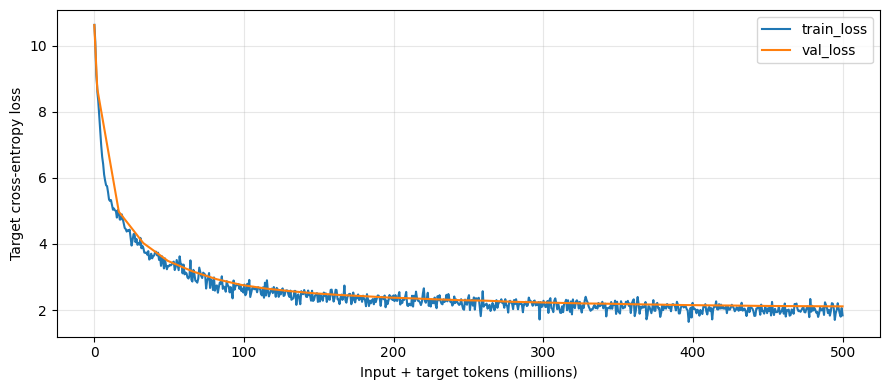

In [11]:
import matplotlib.pyplot as plt
rows=[json.loads(line) for line in (RUN_DIR/'metrics.jsonl').read_text().splitlines()]
fig,ax=plt.subplots(figsize=(9,4))
for key in ('train_loss','val_loss'):
    selected=[r for r in rows if key in r]
    ax.plot([r['total_data_tokens']/1e6 for r in selected],[r[key] for r in selected],label=key)
ax.set(xlabel='Input + target tokens (millions)',ylabel='Target cross-entropy loss')
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(RUN_DIR/'loss_curve.png',dpi=150); plt.show()


## 5. Generate and evaluate

The main policy uses temperatures `[0.0, 0.3, 0.8]`. The earlier dev and test run used `[0.1, 0.5, 0.8]`. Set the temperature list below to choose the corresponding folders. Existing timestamped folders can be set explicitly.

In [4]:
DECODE_CONFIG=dict(temperatures=[0.0,0.3,0.8],top_p=0.95,max_new_tokens=4096,no_repeat_ngram=4,seed=42)
GENERATION_CHECKPOINT=RUN_DIR/'best.pt'

# Separate folders for the two recorded policies.
if DECODE_CONFIG['temperatures'] == [0.1, 0.5, 0.8]:
    DEV_OUT = Path('/kaggle/working/model3_dev')
    TEST_OUT = Path('/kaggle/working/model3_test')
else:
    DEV_OUT = Path('/kaggle/working/model3_dev_t0_t03_t08')
    TEST_OUT = Path('/kaggle/working/model3_test_t0_t03_t08')
print('Using best validation checkpoint; this may precede the final training step.')

Using best validation checkpoint; this may precede the final training step.


In [ ]:
class IncompleteGeneration(RuntimeError): pass

@torch.inference_mode()
def generate_one(model,tok,prompt,device,cfg,seed):
    ids=tok.encode(prompt).ids; context=model.config['context']
    if not ids or len(ids)>=context:
        raise ValueError(f'Prompt has {len(ids)} tokens; context is {context}. No silent truncation.')
    attempts=[]; n=cfg['no_repeat_ngram']
    for attempt,temperature in enumerate(cfg['temperatures']):
        torch.manual_seed((seed+attempt)%2**32)
        history=list(ids); new=[]; past=None; offset=0
        x=torch.tensor([ids],device=device); followers=defaultdict(set)
        for _ in range(cfg['max_new_tokens']):
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type=='cuda'):
                logits,past=model(x,past=past,position_offset=offset,cache=True)
            logits=logits[0].float()
            if not torch.isfinite(logits).all(): raise RuntimeError('Non-finite generation logits')
            logits[[PAD,UNK,BOS,EOS]]=-float('inf')
            if len(new)>=n-1:
                banned=followers.get(tuple(new[-(n-1):]),())
                if banned: logits[list(banned)]=-float('inf')
            if not torch.isfinite(logits).any(): break
            if temperature==0: nxt=int(logits.argmax())
            else:
                probs=torch.softmax(logits/temperature,dim=-1)
                probs,order=probs.sort(descending=True)
                probs[probs.cumsum(0)-probs>cfg['top_p']]=0
                nxt=int(order[torch.multinomial(probs,1)])
            history.append(nxt); new.append(nxt)
            if len(new)>=n: followers[tuple(new[-n:-1])].add(new[-1])
            words=tok.decode(new).split()
            if len(words)>=129:
                return ' '.join(words[:128]),dict(temperature=temperature,attempt=attempt+1,
                    generated_tokens=len(new),prior_failures=attempts)
            consumed=offset+x.shape[1]
            if consumed>=context:
                past=None; offset=0; x=torch.tensor([history[-context:]],device=device)
            else:
                offset=consumed; x=torch.tensor([[nxt]],device=device)
        attempts.append(dict(temperature=temperature,generated_tokens=len(new),words=len(tok.decode(new).split())))
        del past
    raise IncompleteGeneration(json.dumps(attempts))


In [ ]:
def validate_predictions(predictions,prompts):
    if set(predictions)!=set(prompts): raise ValueError('Prediction IDs do not match prompt IDs')
    for k,v in predictions.items():
        if not isinstance(v,dict) or not isinstance(v.get('text'),str) or len(v['text'].split())!=128:
            raise ValueError(f'Prediction {k} must contain exactly 128 words')


In [ ]:
def generate_set(checkpoint_path,run_dir,prompts_path,out,cfg,cpu=False):
    checkpoint_path,run_dir,prompts_path,out=map(Path,(checkpoint_path,run_dir,prompts_path,out))
    if cfg['no_repeat_ngram']<2 or not 0<cfg['top_p']<=1 or not cfg['temperatures'] or min(cfg['temperatures'])<0:
        raise ValueError('Invalid generation settings')
    prompts=load_prompts(prompts_path); out.mkdir(parents=True,exist_ok=True)
    signature=dict(version=VERSION,checkpoint=digest_file(checkpoint_path),
        tokenizer=digest_file(run_dir/'tokenizer.json'),prompts=digest_file(prompts_path),decode=cfg)
    if (out/'generation.json').exists():
        if read_json(out/'generation.json')!=signature: raise ValueError('Generation settings changed; use a new output folder')
    elif any(out.iterdir()): raise ValueError('Nonempty output folder without generation metadata')
    write_json(out/'generation.json',signature)
    ledger=read_json(out/'records.json') if (out/'records.json').exists() else {}
    if not set(ledger)<=set(prompts): raise ValueError('Unknown saved IDs')
    for k,r in ledger.items(): validate_predictions({k:{'text':r['text']}},{k:prompts[k]})
    device=torch.device('cpu' if cpu else 'cuda')
    if not cpu and not torch.cuda.is_available(): raise RuntimeError('Enable GPU for generation')
    state=torch.load(checkpoint_path,map_location='cpu',weights_only=False)
    if state['tokenizer_sha256']!=signature['tokenizer']: raise ValueError('Checkpoint/tokenizer mismatch')
    model=LocalGlobalLM(**state['model_config']); model.load_state_dict(state['model']); del state
    model.to(device).eval(); tok=ScratchByteBPE.from_file(run_dir/'tokenizer.json')
    failures={}
    try:
        for key,record in prompts.items():
            if key in ledger: continue
            seed=(cfg['seed']+int(hashlib.sha256(key.encode()).hexdigest()[:8],16))%2**32
            try:
                text,details=generate_one(model,tok,record['text'],device,cfg,seed)
            except IncompleteGeneration as error:
                failures[key]=str(error); write_json(out/'failures.json',failures)
                print('Could not finish ID',key,'; continuing other prompts.',flush=True); continue
            ledger[key]=dict(text=text,details=details)
            write_json(out/'records.json',ledger)
            write_json(out/'prediction.json',{k:{'text':v['text']} for k,v in ledger.items()})
            if len(ledger)%100==0: print(f'Generated {len(ledger)}/{len(prompts)}',flush=True)
        write_json(out/'failures.json',failures)
        predictions={k:{'text':v['text']} for k,v in ledger.items()}
        if len(predictions)!=len(prompts):
            print(f'INCOMPLETE: {len(predictions)}/{len(prompts)}. No submission ZIP created. See failures.json.')
            return None
        validate_predictions(predictions,prompts)
        write_json(out/'prediction.json',predictions)
        archive=out/'submission.zip'
        with zipfile.ZipFile(str(archive)+'.tmp','w',compression=zipfile.ZIP_DEFLATED) as z:
            z.write(out/'prediction.json','prediction.json')
        with zipfile.ZipFile(str(archive)+'.tmp') as z:
            assert z.namelist()==['prediction.json'] and z.testzip() is None
            validate_predictions(json.loads(z.read('prediction.json'),object_pairs_hook=unique_pairs),prompts)
        os.replace(str(archive)+'.tmp',archive)
        print(f'Validated {len(predictions)} continuations, 128 words each: {archive}')
        return archive
    finally:
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


### Development predictions and official evaluation

In [8]:
dev_archive=generate_set(GENERATION_CHECKPOINT,RUN_DIR,DATA_DIR/'dev_prompts.json',DEV_OUT,DECODE_CONFIG)


Generated 10/212
Generated 20/212
Generated 30/212
Generated 40/212
Generated 50/212
Generated 60/212
Generated 70/212
Generated 80/212
Generated 90/212
Generated 100/212
Generated 110/212
Generated 120/212
Generated 130/212
Generated 140/212
Generated 150/212
Generated 160/212
Generated 170/212
Generated 180/212
Generated 190/212
Generated 200/212
Generated 210/212
Validated 212 continuations, 128 words each: /kaggle/working/model3_dev_1791015107184937549/submission.zip


In [9]:
subprocess.run([sys.executable,'-m','pip','install','-q','bert-score==0.3.13','transformers>=4.45,<5'],check=True)
if EVALUATOR_PATH is None:
    candidates=list(Path('/kaggle/input').rglob('evaluate_phase1.py'))
    if len(candidates)!=1: raise ValueError(f'Set EVALUATOR_PATH explicitly. Found: {candidates}')
    EVALUATOR_PATH=candidates[0]
validate_predictions(read_json(DEV_OUT/'prediction.json'),load_prompts(DATA_DIR/'dev_prompts.json'))
command=[sys.executable,str(EVALUATOR_PATH),'--truth',str(DATA_DIR/'dev_truth.json'),
         '--prediction',str(DEV_OUT/'prediction.json')]
result=subprocess.run(command,capture_output=True,text=True)
print(result.stdout)
if result.stderr: print(result.stderr)
(DEV_OUT/'prof_evaluation.txt').write_text(result.stdout+'\n'+result.stderr,encoding='utf-8')
write_json(DEV_OUT/'evaluator_provenance.json',dict(script_sha256=digest_file(EVALUATOR_PATH),
    truth_sha256=digest_file(DATA_DIR/'dev_truth.json'),prediction_sha256=digest_file(DEV_OUT/'prediction.json'),returncode=result.returncode))
result.check_returncode()


Examples: 212
BERTScore F1: 0.856300
ROUGE-L F1:   0.292600
BLEU-4:       0.191220

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



### Test submission

In [13]:
TEST_PROMPTS=ensure_test_file(ASSET_DIR,LOCAL_TEST_PROMPTS,REPO,TEST_REVISION)
test_archive=generate_set(GENERATION_CHECKPOINT,RUN_DIR,TEST_PROMPTS,TEST_OUT,DECODE_CONFIG)

Official test prompts: 1000 at /kaggle/working/model3_assets/official_phase1_test.json
Generated 10/1000
Generated 20/1000
Generated 30/1000
Generated 40/1000
Generated 50/1000
Generated 60/1000
Generated 70/1000
Generated 80/1000
Generated 90/1000
Generated 100/1000
Generated 110/1000
Generated 120/1000
Generated 130/1000
Generated 140/1000
Generated 150/1000
Generated 160/1000
Generated 170/1000
Generated 180/1000
Generated 190/1000
Generated 200/1000
Generated 210/1000
Generated 220/1000
Generated 230/1000
Generated 240/1000
Generated 250/1000
Generated 260/1000
Generated 270/1000
Generated 280/1000
Generated 290/1000
Generated 300/1000
Generated 310/1000
Generated 320/1000
Generated 330/1000
Generated 340/1000
Generated 350/1000
Generated 360/1000
Generated 370/1000
Generated 380/1000
Generated 390/1000
Generated 400/1000
Generated 410/1000
Generated 420/1000
Generated 430/1000
Generated 440/1000
Generated 450/1000
Generated 460/1000
Generated 470/1000
Generated 480/1000
Generated 

In [19]:
import base64
validate_predictions(read_json(TEST_OUT/'prediction.json'),load_prompts(TEST_PROMPTS))
archive=TEST_OUT/'submission.zip'
assert archive.is_file()
with zipfile.ZipFile(archive) as z:
    assert z.namelist()==['prediction.json'] and z.testzip() is None
    validate_predictions(json.loads(z.read('prediction.json')),load_prompts(TEST_PROMPTS))
encoded=base64.b64encode(archive.read_bytes()).decode('ascii')
display(HTML(f'<a download="model3_local_global_submission.zip" href="data:application/zip;base64,{encoded}">Download submission ZIP</a>'))
